# 01 - Data checks (milestones 1-2)

The VERIFY items of `PROJECT_PLAN.md` §3.1-3.3, run live on your local copies
of Dataset I v2.0, PhysioMotion (ds006386) and the phantom (ds004784).
Same code as `scripts/02_verify_dataset1.py` and `scripts/04_verify_openneuro.py`
(`adr.verify`). Dataset paths come from `configs/paths.yaml` +
`configs/paths.local.yaml`.

Kernel: the `adr` conda environment. Runtime: a few minutes (it loads every
Dataset I subject and every phantom condition).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adr.config import load_paths, package_versions, seed_everything

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
pd.set_option("display.max_columns", 50, "display.width", 200)
paths = load_paths()
seed_everything()
package_versions()

{'python': '3.14.8',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'pandas': '3.0.6',
 'mne': '1.13.2',
 'scikit-learn': '1.9.1',
 'lightgbm': '4.7.0',
 'xgboost': '3.4.2',
 'eelbrain': '0.43.0b0',
 'matplotlib': '3.11.2',
 'mne-icalabel': '0.10.0'}

In [2]:
from adr import verify

{k: str(v) for k, v in paths.items()}

{'dataset1': '/Users/joshuaighalo/Github Dataset/aad_dataset_kuleuven_v2',
 'physiomotion': '/Users/joshuaighalo/Github Dataset/physiomotion_ds006386',
 'phantom': '/Users/joshuaighalo/Github Dataset/phantom_ds004784',
 'own': '/Users/joshuaighalo/Github Repositories/dataset/cocktail',
 'klados': '/Users/joshuaighalo/Github Repositories/dataset/klados_bamidis_2016',
 'cache': '/Users/joshuaighalo/Github Repositories/cocktail-cortical/adr/data/cache',
 'results': '/Users/joshuaighalo/Github Repositories/cocktail-cortical/adr/results',
 'splits': '/Users/joshuaighalo/Github Repositories/cocktail-cortical/adr/splits'}

## Dataset I v2.0 (§3.1)

Channel labels stored in the files vs the standard BioSemi 64 order, the Cz
and C5 indices, an empirical check that channel correlation falls off with
electrode distance (vs shuffled labels), minutes per condition, and whether
every dry stimulus covers its EEG trial.

In [3]:
d1 = verify.dataset1(n_null=50)
per_subject = pd.DataFrame(d1["per_subject"]).T[[
    "n_trials", "labels_match_biosemi64", "cz_index_0based", "c5_index_0based",
    "distance_rho", "distance_rho_null_min", "minutes_hrtf_norep", "minutes_hrtf_all", "minutes_total"]]
per_subject

subjects present: ['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16'] (16 of 16)


S1: 20 trials, sfreq [128.0], labels=biosemi64 True, Cz idx 47, C5 idx 13, dist-rho -0.86 (null min -0.07), HRTF no-rep 26.0 min, HRTF all 38.4 min, total 77.1 min


S2: 20 trials, sfreq [128.0], labels=biosemi64 True, Cz idx 47, C5 idx 13, dist-rho -0.86 (null min -0.04), HRTF no-rep 26.3 min, HRTF all 38.7 min, total 77.1 min


S3: 20 trials, sfreq [128.0], labels=biosemi64 True, Cz idx 47, C5 idx 13, dist-rho -0.75 (null min -0.04), HRTF no-rep 26.3 min, HRTF all 38.7 min, total 77.1 min


S4: 20 trials, sfreq [128.0], labels=biosemi64 True, Cz idx 47, C5 idx 13, dist-rho -0.68 (null min -0.13), HRTF no-rep 26.0 min, HRTF all 38.4 min, total 77.1 min


...

S15: 20 trials, sfreq [128.0], labels=biosemi64 True, Cz idx 47, C5 idx 13, dist-rho -0.85 (null min -0.06), HRTF no-rep 26.3 min, HRTF all 38.7 min, total 77.1 min


S16: 20 trials, sfreq [128.0], labels=biosemi64 True, Cz idx 47, C5 idx 13, dist-rho -0.81 (null min -0.06), HRTF no-rep 26.0 min, HRTF all 38.4 min, total 77.1 min


labels identical across subjects: True


trials where a dry stimulus is shorter than the EEG: 0


,n_trials,labels_match_biosemi64,cz_index_0based,c5_index_0based,distance_rho,distance_rho_null_min,minutes_hrtf_norep,minutes_hrtf_all,minutes_total
S1,20,True,47,13,-0.863415,-0.067419,26.0,38.4,77.066667
S2,20,True,47,13,-0.856928,-0.044809,26.266667,38.666667,77.066667
S3,20,True,47,13,-0.749173,-0.038694,26.266667,38.666667,77.066667
S4,20,True,47,13,-0.683607,-0.130477,26.0,38.4,77.066667
S5,20,True,47,13,-0.823323,-0.055239,26.0,38.4,77.066667
S6,20,True,47,13,-0.895787,-0.094097,26.266667,38.666667,77.066667
S7,20,True,47,13,-0.521304,-0.041661,26.266667,38.666667,77.066667
S8,20,True,47,13,-0.422966,-0.06989,26.0,38.4,77.066667
S9,20,True,47,13,-0.808545,-0.088423,26.0,38.4,77.066667
S10,20,True,47,13,-0.748838,-0.071916,26.266667,38.666667,77.066667


In [4]:
print("labels identical across subjects:", d1["labels_identical_across_subjects"])
print("trials where a dry stimulus is shorter than the EEG:", len(d1["stimulus_shorter_than_eeg"]))
print("HRTF minutes incl. repetitions (the paper's '38 min'):",
      per_subject["minutes_hrtf_all"].astype(float).round(1).unique())

labels identical across subjects: True
trials where a dry stimulus is shorter than the EEG: 0
HRTF minutes incl. repetitions (the paper's '38 min'): [38.4 38.7]


## PhysioMotion (§3.2)

Licence, channel overlap with BioSemi 64, the annotation label list, and
whether any artifact annotation falls inside a rest block.

In [5]:
pm = verify.physiomotion()
print("licence:", pm["licence"], "| subjects:", pm["n_subjects"], "| channels:", pm["n_channels"], "at", pm["sfreq"], "Hz")
print("shared with BioSemi 64:", len(pm["shared_with_biosemi64"]),
      "| PhysioMotion only:", pm["physiomotion_only"], "| BioSemi only:", pm["biosemi64_only"])
print("annotations on", len(pm["annotation_bipolar_pairs"]), "bipolar pairs over", len(pm["annotation_electrodes"]),
      "electrodes, plus", pm["annotation_channels_nonbipolar"])
print("artifact annotations inside rest blocks:", pm["artifact_annotations_inside_base_blocks"],
      "of", pm["n_base_blocks"], "rest blocks")
pd.Series(pm["labels"], name="annotations").to_frame()

licence: CC0 | subjects: 30 | channels: 59 at 1000.0 Hz
shared with BioSemi 64: 57 | PhysioMotion only: ['PO5', 'PO6'] | BioSemi only: ['P1', 'P9', 'Iz', 'CPz', 'AFz', 'P2', 'P10']
annotations on 34 bipolar pairs over 19 electrodes, plus ['ALL']
artifact annotations inside rest blocks: 0 of 536 rest blocks


,annotations
hor_headm,23588
tongue,10919
blink_hor_headm,7378
ver_headm,5195
eyebrow,4811
tongue_eyebrow,3501
swallow,3285
ver_eyem,2958
blink,2613
hor_eyem,2478


### Window labels for one run

How the bipolar annotations become per-window labels (OR rule, 1 s windows,
0.5 s step): coloured rows are labelled windows; white gaps are unannotated
task time (`unlabelled`, excluded from training).

rest           479
ocular         237
muscle         148
motion         161
unlabelled    1570
dtype: int64

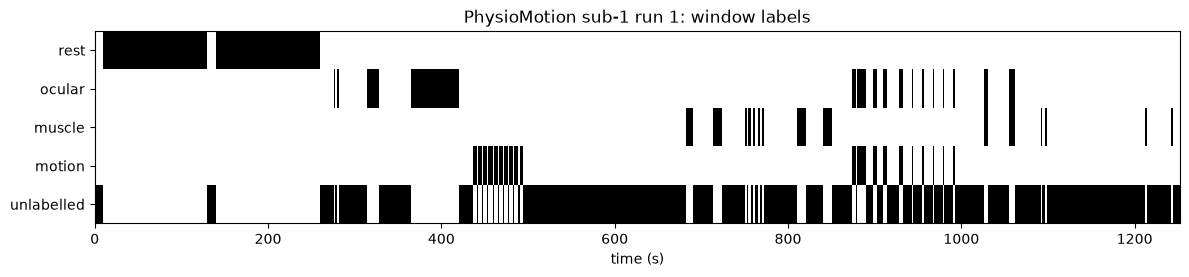

In [6]:
from adr.io import physiomotion as pm_io

ann = pm_io.load_annotations(1, 1)
labels = pm_io.window_labels(ann, duration=1252, window=1.0, step=0.5)
rows = ["rest", "ocular", "muscle", "motion", "unlabelled"]
fig, ax = plt.subplots(figsize=(14, 2.5))
ax.imshow(labels[rows].to_numpy().T, aspect="auto", interpolation="nearest", cmap="Greys",
          extent=[0, labels["stop"].iloc[-1], len(rows) - 0.5, -0.5])
ax.set_yticks(range(len(rows)), rows)
ax.set_xlabel("time (s)")
ax.set_title("PhysioMotion sub-1 run 1: window labels")
labels[rows].sum()

## Phantom (§3.3)

One 5-min trial per condition; the broadcast ground-truth waveforms are
stretched onto the EEG clock, then the 10 brain sources are regressed onto
the 128 average-referenced scalp channels (1-40 Hz). Median R² by lag should
peak at 0.

In [7]:
ph = verify.phantom()
pd.DataFrame({task: {**{f"lag {k}": v for k, v in t["median_r2_brain_gt_by_lag"].items()},
                      "trial s": t["trial_seconds"], "scalp": t["channels"]["scalp"]}
              for task, t in ph["tasks"].items()}).T.round(3)

phantom Brain   1 trial(s), 300.0 s at 512 Hz, median R2 (brain GT -> scalp) lag0 0.640


phantom Eyes    1 trial(s), 300.0 s at 512 Hz, median R2 (brain GT -> scalp) lag0 0.243


phantom Facial  1 trial(s), 300.0 s at 512 Hz, median R2 (brain GT -> scalp) lag0 0.311


phantom Neck    1 trial(s), 300.0 s at 512 Hz, median R2 (brain GT -> scalp) lag0 0.499


phantom Walking 1 trial(s), 300.0 s at 512 Hz, median R2 (brain GT -> scalp) lag0 0.428


phantom All     1 trial(s), 300.0 s at 512 Hz, median R2 (brain GT -> scalp) lag0 0.099


,lag -3,lag -2,lag -1,lag 0,lag 1,lag 2,lag 3,trial s,scalp
Brain,0.389,0.522,0.598,0.640,0.613,0.522,0.382,299.992,128.0
Eyes,0.158,0.194,0.225,0.243,0.237,0.204,0.149,299.992,128.0
Facial,0.202,0.263,0.302,0.311,0.291,0.243,0.180,299.992,128.0
Neck,0.285,0.380,0.465,0.499,0.496,0.431,0.326,299.992,128.0
Walking,0.270,0.349,0.415,0.428,0.393,0.326,0.235,299.992,128.0
All,0.069,0.078,0.090,0.099,0.098,0.086,0.066,299.992,128.0


Text(0.5, 1.0, 'Phantom brain-only: recorded vs ground truth')

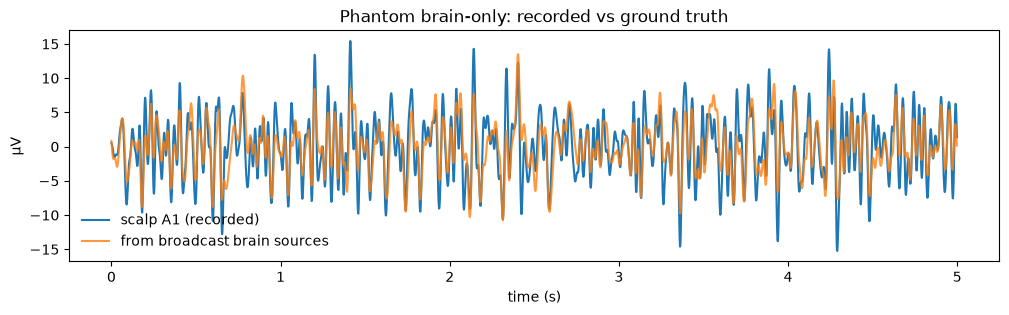

In [8]:
from adr.io import phantom
import scipy.signal

trial = phantom.load_trial("Brain")
sos = scipy.signal.butter(4, [1, 40], "bandpass", fs=trial.sfreq, output="sos")
seg = slice(0, int(5 * trial.sfreq))
eeg = scipy.signal.sosfiltfilt(sos, trial.eeg - trial.eeg.mean(1, keepdims=True), axis=0)[seg]
src = scipy.signal.sosfiltfilt(sos, trial.brain_sources, axis=0)[seg]
beta, *_ = np.linalg.lstsq(src, eeg, rcond=None)
ch = trial.ch_names.index("A1")
t = np.arange(len(eeg)) / trial.sfreq
plt.figure(figsize=(12, 3))
plt.plot(t, eeg[:, ch] * 1e6, label="scalp A1 (recorded)")
plt.plot(t, (src @ beta)[:, ch] * 1e6, label="from broadcast brain sources", alpha=0.8)
plt.xlabel("time (s)"); plt.ylabel("µV"); plt.legend(frameon=False); plt.title("Phantom brain-only: recorded vs ground truth")